In [2]:
# importing libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn import linear_model

In [3]:
#read data set and save to waves
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')
#remove the listed columns
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
#filter out bad data
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

#drop listed columns
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [4]:
#create x data values which include everything except for wave height
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
#create y value data set with just wave height
df_y = wavesML['WVHT'].to_numpy()

In [5]:
#split into test and train data
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
#further split train data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [6]:
#run Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(random_state=25)
#fit model using training data
dt_regressor.fit(X_train, y_train)
#run prediction with validation set
val_pred= dt_regressor.predict(X_val)
# Predict for each other dataset
train_pred = dt_regressor.predict(X_train)
test_pred = dt_regressor.predict(X_test)

# Compare predictions with their matching actual values
train_mse = mean_squared_error(y_train, train_pred)
val_mse = mean_squared_error(y_val, val_pred)
test_mse = mean_squared_error(y_test, test_pred)

print("Training MSE:", train_mse)
print("Validation MSE:", val_mse)
print("Test MSE:", test_mse)

Training MSE: 3.451368541413564e-05
Validation MSE: 0.1354579421221865
Test MSE: 0.12026012731481482


In [7]:
#run Random Forest Regressor with 25 trees
regRF = RandomForestRegressor(n_estimators=25, random_state=30)
#fit model with training data
regRF.fit(X_train, y_train)
#predict on validation data
y_Pred_rf_val= regRF.predict(X_val)
#predict on other data sets
y_Pred_rf_train=regRF.predict(X_train)
y_Pred_rf_test=regRF.predict(X_test)
#calculate mean square error from all data sets
val_mse_rf= mean_squared_error(y_val, y_Pred_rf_val)
train_mse_rf= mean_squared_error(y_train, y_Pred_rf_train)
test_mse_rf= mean_squared_error(y_test, y_Pred_rf_test)
print("Validation MSE:",val_mse_rf)           
print("Training MSE:",train_mse_rf)  
print("Test MSE:",test_mse_rf)  

Validation MSE: 0.07745932584831725
Training MSE: 0.01281397155325515
Test MSE: 0.07215392725742052


In [8]:
#run linear regression
reg= linear_model.LinearRegression()
reg.fit(X_train,y_train)
yPred_lin_train = reg.predict(X_train)
yPred_lin_val= reg.predict(X_val)
yPred_lin_test= reg.predict(X_test)
val_lin_mse= mean_squared_error(y_val,yPred_lin_val)
train_lin_mse= mean_squared_error(y_train,yPred_lin_train)
test_lin_mse= mean_squared_error(y_test,yPred_lin_test)
print("Validation MSE:",val_lin_mse)
print("Training MSE:",train_lin_mse)
print("Test MSE:",test_lin_mse)

Validation MSE: 0.21137167152177652
Training MSE: 0.19381599115382392
Test MSE: 0.19690214837058517


In [9]:
#1.  The decision tree regressor had the lowest mean square error on the training data.  For all of them, the lowest mse
#value was on the training data.  The second lowest for all was the test data.
#2. Cost function for decision tree is squared error.  Cost function for random forest regressor is also
#squared error.
#3. No hyperparameters were optimized.  Fitting and prediction was only ran once.
#5 should have two lines, one for training and one for validation error

In [10]:
#split into test and train data second time
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(df_X, df_y, test_size=0.10)
#further split train data second time
X_train_2, X_val_2, y_train_2, y_val_2 = train_test_split(X_train_2, y_train_2, test_size=0.10)

In [11]:
#rerun decision tree regressor
#run Decision Tree Regressor
dt_regressor_2 = DecisionTreeRegressor(random_state=25)
#fit model using training data
dt_regressor_2.fit(X_train_2, y_train_2)
#run prediction with validation set
val_pred_2= dt_regressor_2.predict(X_val_2)
# Predict for each other dataset
train_pred_2 = dt_regressor_2.predict(X_train_2)
test_pred_2 = dt_regressor_2.predict(X_test_2)

# Compare predictions with their matching actual values
train_mse_2 = mean_squared_error(y_train_2, train_pred_2)
val_mse_2 = mean_squared_error(y_val_2, val_pred_2)
test_mse_2 = mean_squared_error(y_test_2, test_pred_2)

print("Training MSE:", train_mse_2)
print("Validation MSE:", val_mse_2)
print("Test MSE:", test_mse_2)

Training MSE: 3.68398484956764e-05
Validation MSE: 0.14310363344051447
Test MSE: 0.14966629050925928


In [12]:
#rerun Random Forest Regressor with 25 trees
regRF_2 = RandomForestRegressor(n_estimators=25, random_state=30)
#fit model with training data
regRF_2.fit(X_train_2, y_train_2)
#predict on validation data
y_Pred_rf_val_2= regRF_2.predict(X_val_2)
#predict on other data sets
y_Pred_rf_train_2=regRF_2.predict(X_train_2)
y_Pred_rf_test_2=regRF_2.predict(X_test_2)
#calculate mean square error from all data sets
val_mse_rf_2= mean_squared_error(y_val_2, y_Pred_rf_val_2)
train_mse_rf_2= mean_squared_error(y_train_2, y_Pred_rf_train_2)
test_mse_rf_2= mean_squared_error(y_test_2, y_Pred_rf_test_2)
print("Validation MSE:",val_mse_rf_2)           
print("Training MSE:",train_mse_rf_2)  
print("Test MSE:",test_mse_rf_2)  

Validation MSE: 0.08909282948312967
Training MSE: 0.012338329425215361
Test MSE: 0.09012019961358024


In [13]:
#rerun linear model
#run linear regression
reg_2= linear_model.LinearRegression()
reg_2.fit(X_train_2,y_train_2)
yPred_lin_train_2 = reg.predict(X_train_2)
yPred_lin_val_2= reg.predict(X_val_2)
yPred_lin_test_2= reg.predict(X_test_2)
val_lin_mse_2= mean_squared_error(y_val_2,yPred_lin_val_2)
train_lin_mse_2= mean_squared_error(y_train_2,yPred_lin_train_2)
test_lin_mse_2= mean_squared_error(y_test_2,yPred_lin_test_2)
print("Validation MSE:",val_lin_mse_2)
print("Training MSE:",train_lin_mse_2)
print("Test MSE:",test_lin_mse_2)

Validation MSE: 0.19353610879877897
Training MSE: 0.19340857863554492
Test MSE: 0.21625123598779544


In [14]:
#4.  Redoing the train split on the data and rerunning all the models results in slightly different mse values, but not significantly different.  
#The training model was still the one with the lowest mse and the rest still performed well and decision tree regressor had the lowest value.

In [15]:
#create 8 models with different tree numbers
regRF_2t = RandomForestRegressor(n_estimators=2, random_state=30)
regRF_10t = RandomForestRegressor(n_estimators=10, random_state=30)
regRF_25t = RandomForestRegressor(n_estimators=25, random_state=30)
regRF_50t = RandomForestRegressor(n_estimators=50, random_state=30)
regRF_100t = RandomForestRegressor(n_estimators=100, random_state=30)
regRF_250t = RandomForestRegressor(n_estimators=250, random_state=30)
regRF_500t = RandomForestRegressor(n_estimators=500, random_state=30)
regRF_1000t = RandomForestRegressor(n_estimators=1000, random_state=30)
#fit models with training data
regRF_2t.fit(X_train, y_train)
regRF_10t.fit(X_train, y_train)
regRF_25t.fit(X_train, y_train)
regRF_50t.fit(X_train, y_train)
regRF_100t.fit(X_train, y_train)
regRF_250t.fit(X_train, y_train)
regRF_500t.fit(X_train, y_train)
regRF_1000t.fit(X_train, y_train)
#predict on training data
y_Pred_rf2t_train= regRF_2t.predict(X_train)
y_Pred_rf10t_train= regRF_10t.predict(X_train)
y_Pred_rf25t_train= regRF_25t.predict(X_train)
y_Pred_rf50t_train= regRF_50t.predict(X_train)
y_Pred_rf100t_train= regRF_100t.predict(X_train)
y_Pred_rf250t_train= regRF_250t.predict(X_train)
y_Pred_rf500t_train= regRF_500t.predict(X_train)
y_Pred_rf1000t_train= regRF_1000t.predict(X_train)
#predict on validation data
y_Pred_rf2t_val= regRF_2t.predict(X_val)
y_Pred_rf10t_val= regRF_10t.predict(X_val)
y_Pred_rf25t_val= regRF_25t.predict(X_val)
y_Pred_rf50t_val= regRF_50t.predict(X_val)
y_Pred_rf100t_val= regRF_100t.predict(X_val)
y_Pred_rf250t_val= regRF_250t.predict(X_val)
y_Pred_rf500t_val= regRF_500t.predict(X_val)
y_Pred_rf1000t_val= regRF_1000t.predict(X_val)

In [16]:
#calculate MSE for all new models on training data
mse_rf2t =mean_squared_error(y_train, y_Pred_rf2t_train)
mse_rf10t =mean_squared_error(y_train, y_Pred_rf10t_train)
mse_rf25t =mean_squared_error(y_train, y_Pred_rf25t_train)
mse_rf50t =mean_squared_error(y_train, y_Pred_rf50t_train)
mse_rf100t =mean_squared_error(y_train, y_Pred_rf100t_train)
mse_rf250t =mean_squared_error(y_train, y_Pred_rf250t_train)
mse_rf500t =mean_squared_error(y_train, y_Pred_rf500t_train)
mse_rf1000t =mean_squared_error(y_train, y_Pred_rf1000t_train)

#calculate MSE for all new models on validation data
mse_rf2t_val =mean_squared_error(y_val, y_Pred_rf2t_val)
mse_rf10t_val =mean_squared_error(y_val, y_Pred_rf10t_val)
mse_rf25t_val =mean_squared_error(y_val, y_Pred_rf25t_val)
mse_rf50t_val =mean_squared_error(y_val, y_Pred_rf50t_val)
mse_rf100t_val =mean_squared_error(y_val, y_Pred_rf100t_val)
mse_rf250t_val =mean_squared_error(y_val, y_Pred_rf250t_val)
mse_rf500t_val =mean_squared_error(y_val, y_Pred_rf500t_val)
mse_rf1000t_val =mean_squared_error(y_val, y_Pred_rf1000t_val)

In [17]:
mse_data = pd.DataFrame({
    "Number of Trees": [2, 10, 25, 50, 100, 250, 500, 1000],
    "Train MSE": [mse_rf2t, mse_rf10t, mse_rf25t, mse_rf50t, mse_rf100t, mse_rf250t,mse_rf500t, mse_rf1000t],
    "Val MSE": [mse_rf2t_val, mse_rf10t_val, mse_rf25t_val, mse_rf50t_val, mse_rf100t_val, mse_rf250t_val, mse_rf500t_val, mse_rf1000t_val ]
})
print(mse_data)

   Number of Trees  Train MSE   Val MSE
0                2   0.035518  0.110395
1               10   0.015897  0.081119
2               25   0.012814  0.077459
3               50   0.011959  0.074706
4              100   0.011397  0.074004
5              250   0.011016  0.073116
6              500   0.010833  0.072998
7             1000   0.010757  0.072800


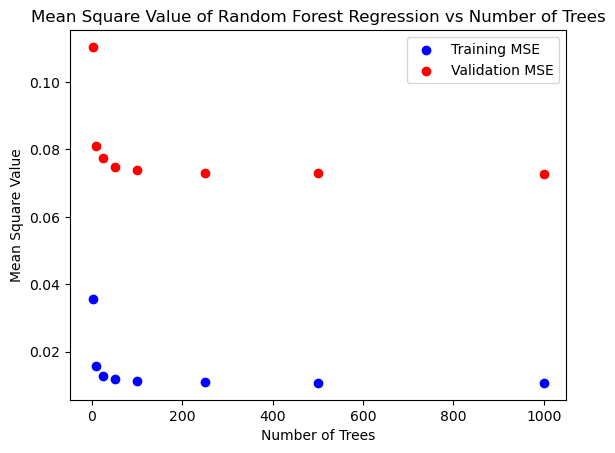

In [18]:
#plot training data and validation data mse values
plt.scatter(mse_data["Number of Trees"], mse_data["Train MSE"]
           ,color="blue", label="Training MSE")
plt.scatter(mse_data["Number of Trees"],mse_data["Val MSE"]
           ,color= "red", label="Validation MSE")
plt.xlabel("Number of Trees")
plt.ylabel("Mean Square Value")
plt.title("Mean Square Value of Random Forest Regression vs Number of Trees")
plt.legend()
plt.show()

In [19]:
#6. I don't see evidence of overfitting with the 1,000 tree data set.  Both MSE values decreased as the number of trees increased. 
#With the Trainin MSE values being the lowest.